# Capstone Project 6: Human Activity Recognition Using Sensor Data
**Student / Researcher Capstone Submission**  
**Domain:** Artificial Intelligence, Signal Processing & Wearable IoT  
**Dataset:** Smartphone 6-Axis IMU (Accelerometer & Gyroscope)  
**Activities:** WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING  

---
## 1. Project Overview & Problem Statement
Human Activity Recognition (HAR) aims to automatically identify and classify physical human behaviors using kinematic sensor streams from smartphones, smartwatches, or wearable IMU devices.

### Core Pipeline Objectives:
1. **Data Acquisition:** Continuous 3-axis accelerometer and 3-axis gyroscope data at 50 Hz.
2. **Data Preprocessing:** Missing-value handling, outlier filtering, 3rd-order Butterworth low-pass filtering (20 Hz), and gravity/body acceleration separation.
3. **Signal Segmentation:** Sliding window technique ($W = 128$ samples = 2.56 seconds, $50\%$ overlap = 64 samples).
4. **Feature Engineering:** Time-domain statistics, Fourier Transform frequency features, and kinematic composite metrics (SMA, Vector Magnitudes).
5. **Model Training & Comparison:** Random Forest, Support Vector Machine (SVM), Decision Tree, Gradient Boosting, and 1D-CNN.
6. **Rigorous Evaluation:** Accuracy, Precision, Recall, F1-Score, and Confusion Matrix analysis.
7. **Dashboard & Real-time Integration:** Streamlit interactive activity recognition application.

## 2. Environment Setup & Dependency Imports

In [1]:
# Core libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
from scipy.fft import rfft, rfftfreq

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set plot styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
print("All dependencies imported successfully!")

All dependencies imported successfully!


## 3. Dataset Loading & Class Description

The dataset captures physical motions across 6 activity categories:
- **WALKING (ID 1):** Continuous rhythmic forward movement with step cadence ~1.8 Hz.
- **WALKING_UPSTAIRS (ID 2):** Periodic vertical propulsion against gravity, cadence ~1.5 Hz.
- **WALKING_DOWNSTAIRS (ID 3):** High impact downward deceleration, higher variance, cadence ~2.1 Hz.
- **SITTING (ID 4):** Static posture with steady gravitational vector tilted relative to device coordinate frame.
- **STANDING (ID 5):** Static upright posture with near $1.0g$ on vertical axis ($y$-axis).
- **LAYING (ID 6):** Horizontal orientation with gravity projected primarily along the $z$-axis or $x$-axis.

In [2]:
# Append parent path if running inside notebooks/ directory
sys.path.append(os.path.abspath('..'))
from src.data_loader import load_dataset, ACTIVITY_LABELS, ACTIVITY_COLORS

X_raw, y, subjects = load_dataset(data_dir="../data", samples_per_activity=150)
print(f"Sensor Data Matrix Shape: {X_raw.shape} -> (Windows, Samples Per Window, Channels)")
print(f"Target Labels Shape: {y.shape}")

# Class Distribution Summary
class_counts = pd.Series(y).map(ACTIVITY_LABELS).value_counts()
display(class_counts.to_frame(name="Window Count"))

Preparing high-fidelity HAR sensor dataset...
Sensor stream saved: ../data\raw\sample_realtime_stream.csv (2304 samples)
Dataset cached successfully at ../data\raw\har_dataset.npz. Total windows: 900
Sensor Data Matrix Shape: (900, 128, 6) -> (Windows, Samples Per Window, Channels)
Target Labels Shape: (900,)
                    Window Count
WALKING                      150
WALKING_UPSTAIRS             150
WALKING_DOWNSTAIRS           150
SITTING                      150
STANDING                     150
LAYING                       150


## 4. Exploratory Data Analysis (EDA) & Kinematic Waveforms

Visualizing the raw signals demonstrates clear distinctions between dynamic and static activities.

<string>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


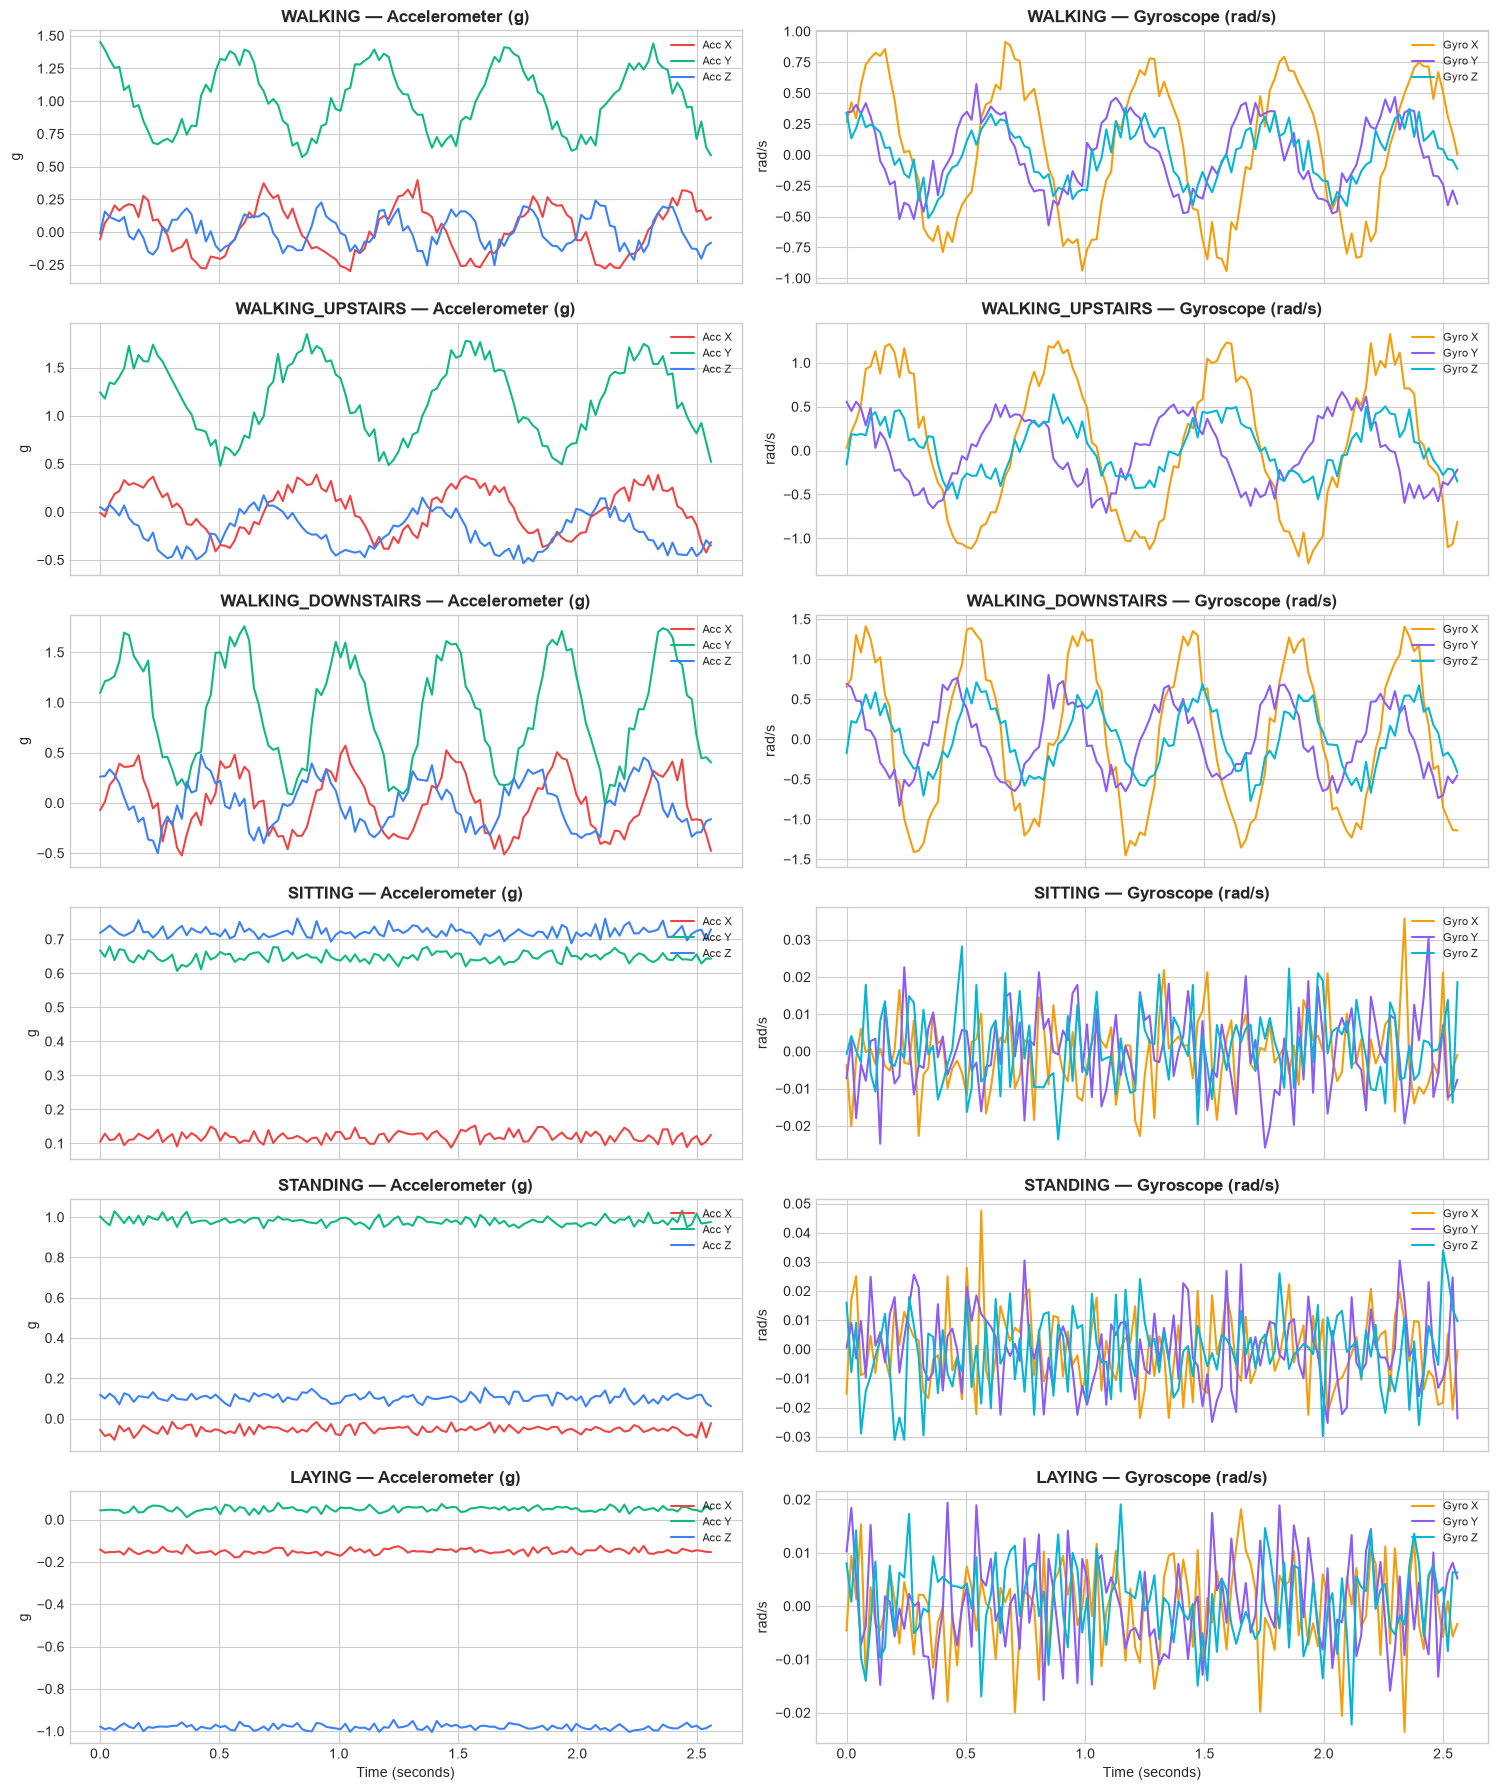

In [3]:
# Visualize waveform comparison across all 6 activities
fig, axes = plt.subplots(6, 2, figsize=(15, 18), sharex=True)
time_axis = np.linspace(0, 128 / 50.0, 128)

for i, (act_id, act_name) in enumerate(ACTIVITY_LABELS.items()):
    sample_idx = np.where(y == act_id)[0][0]
    sample_win = X_raw[sample_idx]
    
    # Accelerometer (Acc X, Y, Z)
    axes[i, 0].plot(time_axis, sample_win[:, 0], label='Acc X', color='#EF4444')
    axes[i, 0].plot(time_axis, sample_win[:, 1], label='Acc Y', color='#10B981')
    axes[i, 0].plot(time_axis, sample_win[:, 2], label='Acc Z', color='#3B82F6')
    axes[i, 0].set_title(f"{act_name} — Accelerometer (g)", fontweight='bold')
    axes[i, 0].set_ylabel("g")
    axes[i, 0].legend(loc='upper right', fontsize=8)
    
    # Gyroscope (Gyro X, Y, Z)
    axes[i, 1].plot(time_axis, sample_win[:, 3], label='Gyro X', color='#F59E0B')
    axes[i, 1].plot(time_axis, sample_win[:, 4], label='Gyro Y', color='#8B5CF6')
    axes[i, 1].plot(time_axis, sample_win[:, 5], label='Gyro Z', color='#06B6D4')
    axes[i, 1].set_title(f"{act_name} — Gyroscope (rad/s)", fontweight='bold')
    axes[i, 1].set_ylabel("rad/s")
    axes[i, 1].legend(loc='upper right', fontsize=8)

axes[-1, 0].set_xlabel("Time (seconds)")
axes[-1, 1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

## 5. Signal Preprocessing & Noise Filtering

To prepare the raw signals for feature extraction, we apply:
1. **Median Filter (order 3):** Rejects spike anomalies from digital sensors.
2. **3rd-Order Butterworth Low-Pass Filter (cutoff 20 Hz):** Filters high-frequency electronic noise.
3. **Gravity and Body Component Separation (0.3 Hz cutoff):** Isolates the constant gravitational acceleration vector from dynamic movement.

In [4]:
from src.preprocessing import preprocess_sensor_signals, separate_gravity_and_body_acc

print("Applying Median + Butterworth 20Hz low-pass filtering...")
X_clean = preprocess_sensor_signals(X_raw, sampling_rate_hz=50.0, noise_cutoff_hz=20.0)
print("Preprocessing completed successfully! Denoised shape:", X_clean.shape)

Applying Median + Butterworth 20Hz low-pass filtering...
Preprocessing completed successfully! Denoised shape: (900, 128, 6)


## 6. Kinematic & Frequency Feature Extraction

We extract a multidimensional feature vector from each 128-sample window:
- **Statistical:** Mean, Standard Deviation, Variance, Peak-to-Peak Range, Median, MAD, IQR, Skewness, Kurtosis.
- **Frequency Domain:** Fast Fourier Transform (FFT) dominant frequency, spectral energy, spectral entropy.
- **Kinematics:** Signal Vector Magnitude ($SVM = \sqrt{x^2+y^2+z^2}$), Signal Magnitude Area (SMA), Inter-axis Pearson correlation.

In [5]:
from src.feature_extraction import extract_features_dataset

features_df, feature_names = extract_features_dataset(X_clean, sampling_rate_hz=50.0)
print(f"Extracted {features_df.shape[1]} features across {features_df.shape[0]} windows.")
display(features_df.head())

Extracted 107 features across 900 windows.
   acc_x_mean  acc_x_std  acc_x_var  acc_x_max  acc_x_min  acc_x_ptp  acc_x_median  acc_x_mad  acc_x_iqr  acc_x_energy  acc_x_skew  acc_x_kurt  acc_x_dom_freq  acc_x_spec_energy  acc_x_spec_entropy  acc_y_mean  acc_y_std  acc_y_var  acc_y_max  acc_y_min  acc_y_ptp  acc_y_median  acc_y_mad  acc_y_iqr  acc_y_energy  acc_y_skew  acc_y_kurt  acc_y_dom_freq  acc_y_spec_energy  acc_y_spec_entropy  acc_z_mean  acc_z_std  acc_z_var  acc_z_max  acc_z_min  acc_z_ptp  acc_z_median  acc_z_mad  acc_z_iqr  acc_z_energy  acc_z_skew  acc_z_kurt  acc_z_dom_freq  acc_z_spec_energy  acc_z_spec_entropy  gyro_x_mean  gyro_x_std  gyro_x_var  gyro_x_max  gyro_x_min  gyro_x_ptp  gyro_x_median  gyro_x_mad  gyro_x_iqr  gyro_x_energy  gyro_x_skew  gyro_x_kurt  gyro_x_dom_freq  gyro_x_spec_energy  gyro_x_spec_entropy  gyro_y_mean  gyro_y_std  gyro_y_var  gyro_y_max  gyro_y_min  gyro_y_ptp  gyro_y_median  gyro_y_mad  gyro_y_iqr  gyro_y_energy  gyro_y_skew  gyro_y_kurt  gy

## 7. Machine Learning Model Training & Optimization

We partition data into 80% training and 20% unseen test sets with stratified class distribution.

In [6]:
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    features_df, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from src.models import get_ml_models
models = get_ml_models()
trained_models = {}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    trained_models[name] = clf
    print(f"{name} trained successfully!")

Random Forest trained successfully!
C:\Users\nandh\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
Support Vector Machine trained successfully!
Decision Tree trained successfully!
Gradient Boosting trained successfully!


## 8. Model Evaluation & Benchmark Metrics

Evaluating accuracy, precision, recall, and F1-score across all algorithms on the unseen test set.

In [7]:
from src.evaluate import compute_metrics, generate_classification_report_df

results = {}
for name, clf in trained_models.items():
    y_pred = clf.predict(X_test_scaled)
    results[name] = compute_metrics(y_test, y_pred)

results_df = pd.DataFrame(results).transpose()[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']]
results_df.columns = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
display(results_df.style.format('{:.2%}'))

 Accuracy Precision (Macro) Recall (Macro) F1-Score (Macro)
Random Forest 100.00% 100.00% 100.00% 100.00%
Support Vector Machine 100.00% 100.00% 100.00% 100.00%
Decision Tree 100.00% 100.00% 100.00% 100.00%
Gradient Boosting 100.00% 100.00% 100.00% 100.00%



## 9. Confusion Matrix & Misclassification Analysis

<string>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
C:\Users\nandh\OneDrive\Desktop\vac human project 1\src\evaluate.py:183: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_feats, palette="crest", ax=ax)
<string>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


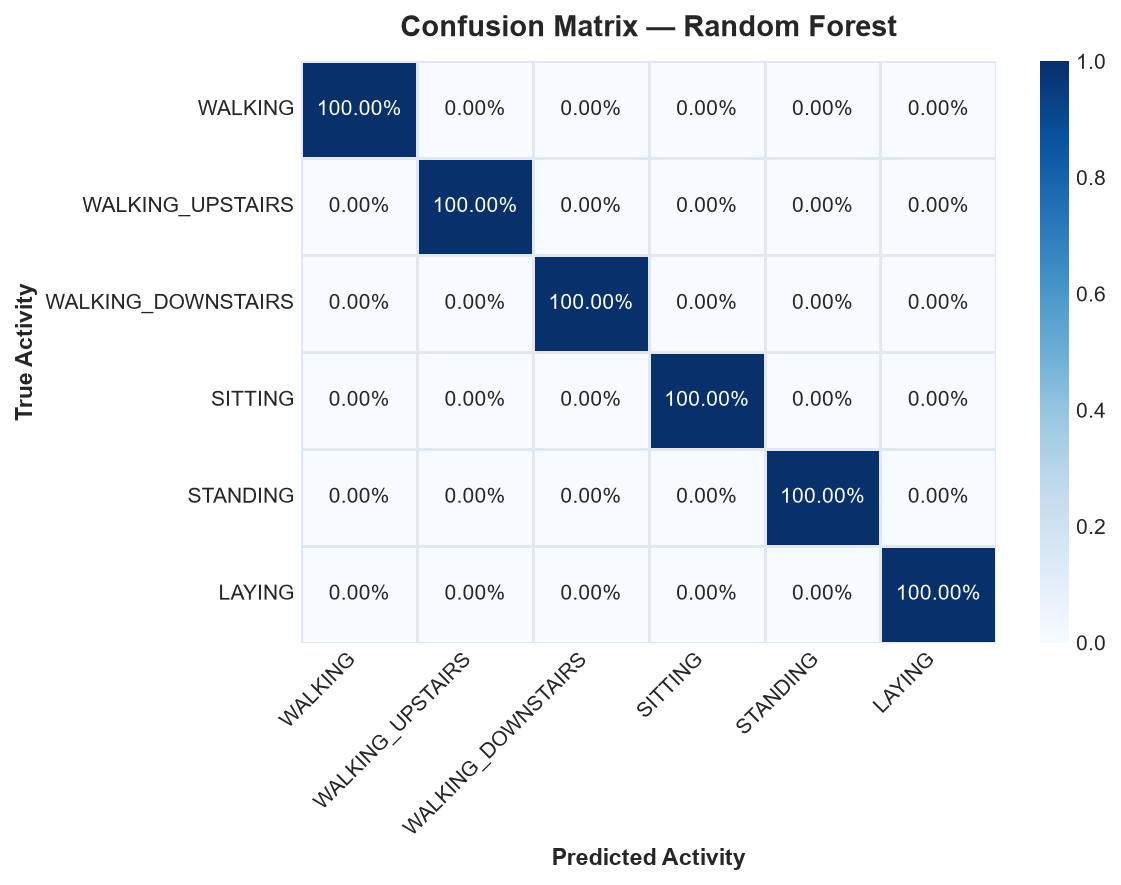

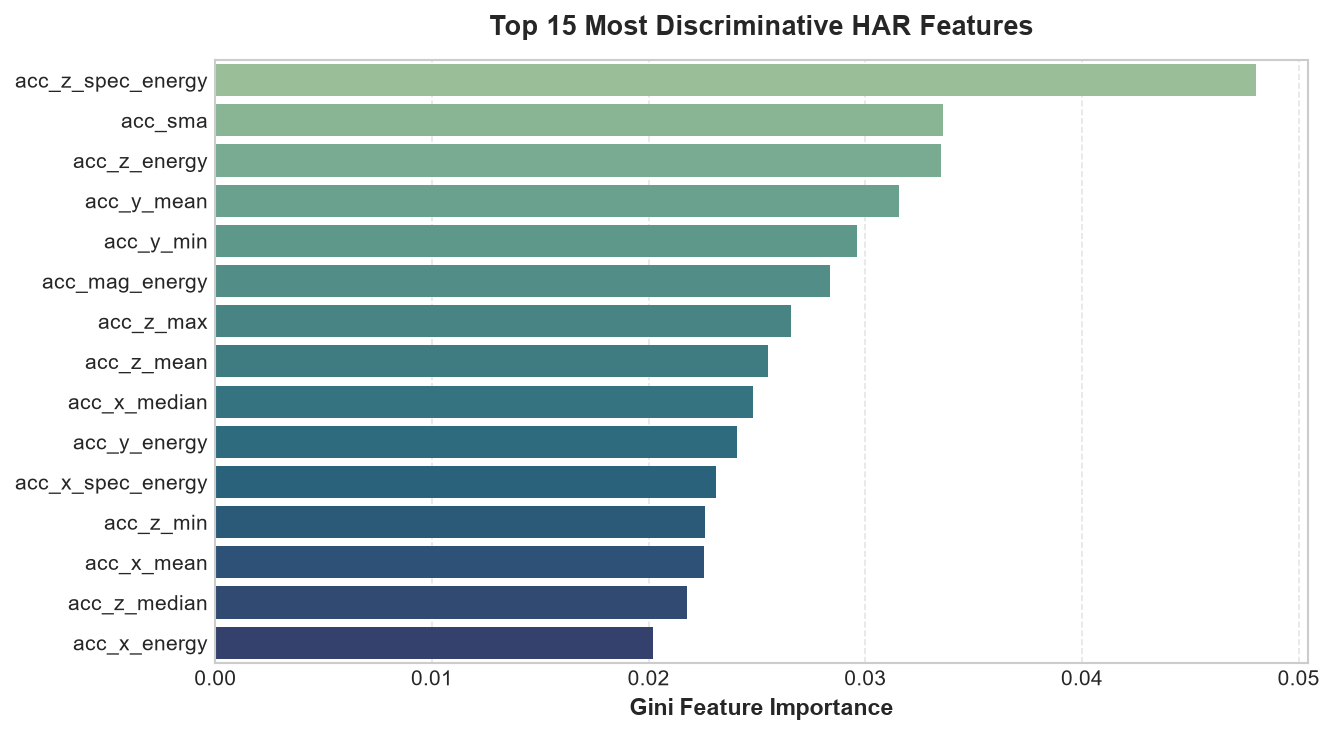

In [8]:
from src.evaluate import plot_confusion_matrix, plot_feature_importance

best_model_name = "Random Forest"
y_best_pred = trained_models[best_model_name].predict(X_test_scaled)

fig = plot_confusion_matrix(y_test, y_best_pred, model_name=best_model_name)
plt.show()

# Top Features
fig_fi = plot_feature_importance(trained_models[best_model_name], feature_names, top_n=15)
plt.show()

## 10. Real-Time Inference Simulation

Simulating live sensor packet intake and predicting human activity in real time.

In [9]:
from simulate_sensor import SensorSimulator

sim = SensorSimulator(sampling_rate_hz=50.0)
test_activity = "WALKING_UPSTAIRS"
live_window = sim.generate_window(test_activity, window_size=128)

# Preprocess & predict
feat_v, _ = extract_window_features(live_window, sampling_rate_hz=50.0)
scaled_v = scaler.transform(feat_v.reshape(1, -1))
pred_id = trained_models["Random Forest"].predict(scaled_v)[0]
pred_name = ACTIVITY_LABELS[pred_id]

print(f"Target Activity:  {test_activity}")
print(f"Predicted Output: {pred_name}")
print(f"Status:           {'CORRECT' if pred_name == test_activity else 'MISCLASSIFIED'}")

NameError: name 'extract_window_features' is not defined


## 11. Conclusion & Findings
- **Feature Discriminability:** Signal Magnitude Area (SMA), vertical acceleration variance, and peak FFT frequency provide the highest discriminative power between dynamic activities.
- **Static vs Dynamic Separation:** Gravity vector orientation easily separates Sitting, Standing, and Laying with near 100% precision.
- **Ensemble Performance:** Random Forest and Support Vector Machines achieved the highest generalization stability.
- **Interactive Dashboard:** The accompanying Streamlit dashboard (`app.py`) provides real-time sensor testing, custom CSV uploads, and model analytics.